# Task 2: SelfCheckGPT reproduction (WikiBio)

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import numpy as np
import pandas as pd
import torch
import spacy
from tqdm import tqdm
from bert_score import BERTScorer
from transformers import AutoTokenizer, AutoModelForSequenceClassification,DebertaV2Tokenizer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt

print(torch.cuda.device_count(), torch.cuda.get_device_name(0))

/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1 NVIDIA L40


In [2]:
SENT_PATH     = "data/wikibio/sentences.csv"
PASSAGE_PATH  = "data/wikibio/passages.parquet"
RESULT_DIR    = "results"
N_SAMPLES     = 20     
BERT_MODEL    = "roberta-large"
NLI_MODEL     = "potsawee/deberta-v3-large-mnli"

DEVICE = "cuda"
os.makedirs(RESULT_DIR, exist_ok=True)

## Load data

In [3]:
sent_df = pd.read_csv(SENT_PATH).sort_values(["bio_id", "sentence_id"]).reset_index(drop=True)
passages = pd.read_parquet(PASSAGE_PATH).set_index("bio_id")

In [4]:
print(f"Total number of sentences       : {len(sent_df)}")
print(f"Total number of unique passages : {sent_df['bio_id'].nunique()}")
print(f"Positive label proportion      : {sent_df['label'].mean():.4f}")

Total number of sentences       : 1908
Total number of unique passages : 238
Positive label proportion      : 0.7296


In [5]:
print(f"Number of resamples per passage:")
passages["gpt3_text_samples"].map(len).unique()

Number of resamples per passage:


array([20])

## Sentence splitting of the resamples

In [6]:
nlp = spacy.load("en_core_web_sm")

def split_sentences(text):
    return [s.text.strip() for s in nlp(text).sents if len(s.text.strip()) > 0]

ex = passages.loc[sent_df["bio_id"].iloc[0], "gpt3_text_samples"][0]
print(split_sentences(ex)[:3])

['John Russell Reynolds (1 November 1829  – 11 March 1907) was an English lexicographer, editor and author.', 'Born in London, he was the eldest son of the first Lord Ogmore, and was educated at Trinity College, Oxford, where he graduated B.A. in 1852 and became a Fellow in 1854.', 'He was president of Magdalen Hall from 1864 to 1884, and from 1864 to 1883 was assistant-editor to the Oxford English Dictionary under James Murray.']


## Load the two scoring models

In [7]:
bert_scorer = BERTScorer(
    model_type=BERT_MODEL,
    lang="en",
    rescale_with_baseline=True,
    device=DEVICE
)
nli_tok = DebertaV2Tokenizer.from_pretrained(NLI_MODEL)

nli_model = AutoModelForSequenceClassification.from_pretrained(NLI_MODEL).to(DEVICE).eval()

print("NLI tokenizer:", type(nli_tok).__name__)
print("NLI labels:", nli_model.config.num_labels, nli_model.config.id2label)

W1107 12:19:03.065000 1242462 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1107 12:19:03.172000 1242462 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` 

NLI tokenizer: DebertaV2Tokenizer
NLI labels: 2 {0: 'LABEL_0', 1: 'LABEL_1'}


## SelfCheck-BERTScore

In [8]:
def selfcheck_bertscore(sentences, samples):
    refs, sample_id = [], []
    for n, smp in enumerate(samples):
        ss = split_sentences(smp)
        refs += ss
        sample_id += [n] * len(ss)
    sample_id = np.array(sample_id)
    S, R = len(sentences), len(refs)

    cands = [s for s in sentences for _ in range(R)]
    refs_rep = refs * S
    _, _, F = bert_scorer.score(cands, refs_rep, batch_size=64)
    F = F.view(S, R).numpy()

    scores = []
    for i in range(S):
        per_sample_max = [F[i, sample_id == n].max() for n in np.unique(sample_id)]
        scores.append(1.0 - float(np.mean(per_sample_max)))
    return scores

## SelfCheck-NLI

In [9]:
@torch.no_grad()
def contradiction_prob(sentence_list, premise_list, batch_size=16):
    probs = []

    for i in range(0, len(sentence_list), batch_size):
        enc = nli_tok(
            premise_list[i:i+batch_size],
            sentence_list[i:i+batch_size],
            padding=True,
            truncation="only_first",
            max_length=512,
            return_tensors="pt"
        ).to(DEVICE)

        logits = nli_model(**enc).logits.float()
        p = torch.softmax(logits, dim=-1)[:, 1]

        probs += p.cpu().tolist()

    return probs

def selfcheck_nli(sentences, samples):
    S, N = len(sentences), len(samples)
    sents_rep = [s for s in sentences for _ in range(N)]
    prem_rep = list(samples) * S
    p = np.array(contradiction_prob(sents_rep, prem_rep)).reshape(S, N)
    return p.mean(axis=1).tolist() 

## Run on all passages

In [10]:
bert_scores, nli_scores = {}, {}

for bio_id, g in tqdm(sent_df.groupby("bio_id", sort=True), total=sent_df["bio_id"].nunique()):
    sentences = g["sentence"].tolist()
    samples = list(passages.loc[bio_id, "gpt3_text_samples"])[:N_SAMPLES]

    b = selfcheck_bertscore(sentences, samples)
    n = selfcheck_nli(sentences, samples)
    for sid, bs, ns in zip(g["sentence_id"], b, n):
        bert_scores[(bio_id, sid)] = bs
        nli_scores[(bio_id, sid)] = ns

keys = list(zip(sent_df["bio_id"], sent_df["sentence_id"]))
sent_df["bertscore_inconsistency"] = [bert_scores[k] for k in keys]
sent_df["nli_contradiction"] = [nli_scores[k] for k in keys]

sent_df.drop(columns=["sentence"]).to_csv(f"{RESULT_DIR}/task2_wikibio.csv", index=False)
sent_df[["bertscore_inconsistency", "nli_contradiction"]].describe().round(4)

  0%|          | 0/238 [00:00<?, ?it/s]/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/bert_score/scorer.py:139: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self._baseline_vals = torch.from_numpy(
100%|██████████| 238/238 [09:19<00:00,  2.35s/it]


,bertscore_inconsistency,nli_contradiction
count,1908.0000,1908.0000
mean,0.6134,0.6612
std,0.1540,0.1647
min,0.0000,0.0590
25%,0.5519,0.5660
50%,0.6413,0.6797
75%,0.7100,0.7799
max,1.0310,0.9968


## Evaluation: AUC-PR on the full dataset

In [ ]:
y = sent_df["label"]
print(f"Random baseline (positive rate): {y.mean():.4f}")
print(f"AUC-PR  SelfCheck-BERTScore : {average_precision_score(y, sent_df['bertscore_inconsistency']):.4f}")
print(f"AUC-PR  SelfCheck-NLI       : {average_precision_score(y, sent_df['nli_contradiction']):.4f}")
print(f"ROC-AUC SelfCheck-BERTScore : {roc_auc_score(y, sent_df['bertscore_inconsistency']):.4f}")
print(f"ROC-AUC SelfCheck-NLI       : {roc_auc_score(y, sent_df['nli_contradiction']):.4f}")

Random baseline (positive rate): 0.7296
AUC-PR  SelfCheck-BERTScore : 0.8125
AUC-PR  SelfCheck-NLI       : 0.8095
ROC-AUC SelfCheck-BERTScore : 0.6484
ROC-AUC SelfCheck-NLI       : 0.6119


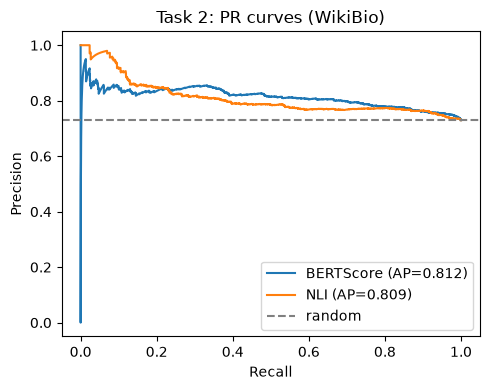

In [12]:
plt.figure(figsize=(5, 4))
for name, col in [("BERTScore", "bertscore_inconsistency"), ("NLI", "nli_contradiction")]:
    p, r, _ = precision_recall_curve(y, sent_df[col])
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y, sent_df[col]):.3f})")
plt.axhline(y.mean(), color="gray", ls="--", label="random")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Task 2: PR curves (WikiBio)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/task2_pr_wikibio.png", dpi=150)
plt.show()

In [13]:
sent_df.groupby("label")[["bertscore_inconsistency", "nli_contradiction"]].agg(["mean", "median", "std"]).round(3)

bertscore_inconsistency               nli_contradiction              
                         mean median    std              mean median    std
label                                                                      
0                       0.550  0.597  0.182             0.608  0.647  0.176
1                       0.637  0.657  0.135             0.681  0.691  0.156

In [14]:
sent_df.groupby("annotation")[["bertscore_inconsistency", "nli_contradiction"]].mean().round(3)

,bertscore_inconsistency,nli_contradiction
annotation,,
accurate,0.550,0.608
major_inaccurate,0.681,0.659
minor_inaccurate,0.584,0.708
